# 10 - Local association and acquisition-candidate diagnostics

## 1. Tujuan dan batas

Tahap ini **tidak mengubah scorer, hint, decoder, boundary, atau label model**. Kita membaca fitur/posisi pemain dari run A2b yang sudah tersimpan, lalu source menghitung asosiasi spasial lokal dan kandidat encounter. Tidak ada ekstraksi fitur ulang, public GT, anotasi manual, atau submission baru.

Track slot/nomor kolom bukan identitas pemain. Asosiasi memakai mutual spatial nearest dalam tim yang sama antar-frame berurutan, speed gate, dan margin alternatif dua arah. Duplicate/crossing yang ambigu ditolak. Gap dan batas babak tidak dijembatani. Link yang unik secara spasial tetap hanya hipotesis; histori dibatasi jendela pendek, tanpa persistent player ID.

Kandidat reception/interception memerlukan pendekatan bola, perubahan gerak, proximity dan hubungan pasca-pertemuan yang stabil pada link yang diterima. Window sesudah anchor memakai lookahead; ini diagnosis offline, belum evidence yang diaktifkan pada model. Kandidat bukan owner atau controlled possession yang terverifikasi.

In [1]:
from pathlib import Path
import sys,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'games.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.artifacts import list_runs,read_json,read_table
from src.player_acquisition_diagnostics import run_player_acquisition_diagnostics,diagnostic_config
pd.set_option('display.max_columns',None)
REFERENCE_RUN_ID='20261116_032142_912812_df9f9049'
reference_dir=next(Path(r['path']) for r in list_runs(project_dir=ROOT) if r['run_id']==REFERENCE_RUN_ID)
reference_manifest=read_json(reference_dir);reference_pass=reference_manifest['final_core_pass']
SETTINGS_CONFIG=ROOT/'config/player_acquisition_diagnostics.yaml'
STORAGE_CONFIG=ROOT/'config/artifacts_player_acquisition.yaml'
settings=diagnostic_config(yaml.safe_load(SETTINGS_CONFIG.read_text(encoding='utf-8-sig')))
assert settings['enabled']
print('Reference predictions reused:',REFERENCE_RUN_ID)
display(settings)
display(yaml.safe_load(STORAGE_CONFIG.read_text(encoding='utf-8-sig')))

{'enabled': True, 'association_max_speed_mps': 12.0, 'association_ambiguity_margin_m': 0.15, 'history_cap_frames': 10, 'pre_frames': 5, 'post_frames': 5, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65, 'minimum_approach_drop_m': 0.5, 'minimum_incoming_speed_mps': 3.0, 'minimum_speed_drop_mps': 2.0, 'minimum_turn_degrees': 30.0, 'minimum_post_support_fraction': 0.8}

{'root_dir': 'artifacts', 'submission_filename': 'diagnostic_only.csv'}

Reference predictions reused: 20261116_032142_912812_df9f9049


## 2. Pengaturan diagnostik

| Pengaturan | Nilai awal | Dasar / batas |
|---|---|---|
| Maksimum step association | 12 m/s / FPS | Menggunakan batas motion lama; bukan bukti identitas |
| Margin alternatif | 0.15 m | Hipotesis awal untuk menolak pasangan yang nyaris setara |
| History cap | 10 frame | Bukan panjang track atau durasi identitas |
| Pre/post window | 5/5 frame | 0.2 s sebelum dan sesudah pada 25 FPS; offline lookahead |
| Radius / relative speed | 2.5 m / 3 m/s | Menggunakan skala proxy sebelumnya |
| Player quality minimum | 0.65 | Gate cakupan, bukan confidence |
| Approach / incoming speed | 0.5 m / 3 m/s | Hipotesis encounter awal |
| Slowdown atau turn | 2 m/s atau 30 derajat | Proxy perubahan gerak, bukan proof of touch |
| Post support | 0.8 | Minimal 80% close dan co-motion dalam post window |

Parameter ini belum dituning terhadap pertandingan atau GT. Window lengkap harus memiliki bola/quality andal dan link yang diterima. Kandidat pendek yang lolos post window masih mungkin; tidak ada minimum possession duration.

## 3. Jalankan diagnostic-only pipeline atau baca run tersimpan

RUN_DIAGNOSTIC=True membaca artefak A2b dan menghasilkan folder run baru. Source memverifikasi checksum input dan menyimpan config/model.json, config/diagnostic.json, config/storage.json, inputs/reference.json dan seluruh tabel hasil. Setelah contoh selesai, default False membuka run yang dipatok. Tidak ada scoring ulang atau submission baru.

In [2]:
RUN_DIAGNOSTIC = False
DIAGNOSTIC_RUN_ID = "20261116_142221_367604_ee14b62c"
if RUN_DIAGNOSTIC:
    diagnostic_dir=Path(run_player_acquisition_diagnostics(reference_dir,settings,project_dir=ROOT,
        storage_config_path=STORAGE_CONFIG,diagnostic_config_source=SETTINGS_CONFIG,
        execution_metadata={'notebook':'notebooks/10_player_association_acquisition_diagnostics.ipynb'}))
else:
    candidates=[r for r in list_runs(project_dir=ROOT)
        if read_json(r['path']).get('execution',{}).get('experiment')=='player_association_acquisition_diagnostics']
    if not candidates:raise RuntimeError('Belum ada run diagnostik; gunakan RUN_DIAGNOSTIC=True')
    diagnostic_dir=next(Path(r['path']) for r in candidates if r['run_id']==DIAGNOSTIC_RUN_ID) if DIAGNOSTIC_RUN_ID else Path(candidates[-1]['path'])
manifest=read_json(diagnostic_dir)
assert manifest['status']=='completed' and manifest['entrypoint']=='player_acquisition_diagnostics'
assert read_json(diagnostic_dir,'config/diagnostic.json')['settings']==settings
assert read_json(diagnostic_dir,'config/model.json')==read_json(reference_dir,'config/model.json')
print('Diagnostic run:',manifest['run_id'],'folder:',diagnostic_dir)
display(read_json(diagnostic_dir,'inputs/reference.json'))

{'run_id': '20261116_032142_912812_df9f9049', 'path': 'C:\\Users\\HP 840\\Documents\\Hizkia ITS\\Lomba\\MBG\\more-than-a-hack-mbg\\artifacts\\20261116_032142_912812_df9f9049', 'files': {'features/initial/frames.csv': '0e5d8d66c1d5020a75a2041e1c4e22a2531d5fcfc14600f0eb7076c69b2a6fb0', 'features/initial/player_positions.csv': '07ad901669e1247d7ee4c8ace11a03cf1abd49f811f7ade4681021cb0325a2e4', 'features/initial/player_positions_metadata.json': '8cc06ba82bdc5173b381ff25ba0f336f6455ad6a9a3472de0a28ab4f154c7f64', 'core/initial/quality/frames.csv': '952076940a3bf7682fc005f86aa8105f56dcd9ba8724137769ce1c585039c810', 'core/initial/fusion/control_components.csv': 'f990d2ce92053f986df3b04044bae2e7737a8ace243c23a93a6bf4adc01c36cc', 'result/labels.csv': '4738654dc999d39504d88d5a6bc79aab48b99f94d848bfd9efa39ceb4945be28', 'core/initial/decode/transitions.csv': 'c0034a6d3b578ce1daf404858703ceb9d9d0186faf36d601edc3d30101df2639'}, 'prediction_policy': 'reuse immutable reference predictions; no scoring o

Diagnostic run: 20261116_142221_367604_ee14b62c folder: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261116_142221_367604_ee14b62c


## 4. Provenance dan schema

Scorer yang dilindungi dibandingkan dengan hash run referensi. Pipeline mendapat cabang audit opsional; pengujian sintetis memastikan mengaktifkannya tidak mengubah skor/hint/label. Untuk pertandingan, label lama digunakan apa adanya dan byte-nya diverifikasi; bukan klaim bahwa model dihitung ulang.

Folder diagnostics/player_acquisition/ menyimpan frames.csv, association_summary.csv, association_coverage.csv, relative_speed_summary.csv, candidate_summary.csv, events.csv dan metadata.json. Folder player_acquisition_reference/ menyimpan konteks prediksi lama; player_acquisition_synthetic/ menyimpan skenario toy.

| Kolom per-side h/a | Makna |
|---|---|
| nearest_index / predecessor_index | Indeks kolom observasi saat ini/sebelumnya; -1 berarti tidak ada link; bukan identitas |
| association_status | linked, ambiguous, unmatched, block_start, no_player, ball_unavailable, outside_half |
| local_history_*_frames | Histori link lokal, dicap; bukan umur track |
| observation_column_changed | Nomor kolom terdekat berubah; belum tentu orang berubah |
| nearest_candidate_switch | Current nearest diasosiasikan ke titik sebelumnya yang berbeda dari previous nearest |
| naive/associated_relative_speed | Perubahan vektor bola-pemain, memakai nearest lama vs kandidat yang diasosiasikan; m/s |
| naive_high_associated_low_near | Naive >3, associated <=3 pada konteks dekat/andal; bukan label false positive |
| candidate / candidate_reason | Proxy encounter dan alasan syarat tidak terpenuhi |
| approach_drop / ball_speed_drop / ball_turn | Meter, m/s, derajat; bukan probabilitas |
| post_close/comotion_fraction | Fraksi dukungan setelah anchor, bukan confidence |

prior_nearest_team dan geometry_team_change pada events hanya geometri sebelum encounter; tidak menyatakan pemegang possession atau interception yang benar.

Beberapa source referensi memakai LF, sedangkan file workspace kini CRLF. Pemeriksaan menerima hanya byte yang identik atau konversi LF/CRLF yang persis cocok dengan hash lama; perubahan karakter source lainnya tetap ditolak. Snapshot dan artefak referensi tidak ditulis ulang.


In [3]:
protected=['src/features.py','src/observation_quality.py','src/team_control.py','src/control_acquisition.py',
           'src/evidence_fusion.py','src/live_dead.py','src/temporal_decoder.py','src/boundary_refinement.py']
reference_hashes={k.replace(chr(92),'/'):v for k,v in reference_manifest['source_sha256'].items()}
source_checks=[]
for name in protected:
    raw=(ROOT/name).read_bytes();lf=raw.replace(b'\r\n',b'\n')
    same=hashlib.sha256(raw).hexdigest()==reference_hashes[name]
    equivalent=any(hashlib.sha256(candidate).hexdigest()==reference_hashes[name] for candidate in [lf,lf.replace(b'\n',b'\r\n')])
    assert same or equivalent,name
    source_checks.append({'source':name,'raw_sha_equal':same,'newline_only_difference':not same and equivalent,'content_equivalent':same or equivalent})
display(pd.DataFrame(source_checks))
label_path=reference_dir/'result/labels.csv'
assert hashlib.sha256(label_path.read_bytes()).hexdigest()==reference_manifest['files']['result/labels.csv']['sha256']
prefix='diagnostics/player_acquisition'
d=read_table(diagnostic_dir,f'{prefix}/frames.csv')
association=read_table(diagnostic_dir,f'{prefix}/association_summary.csv')
coverage=read_table(diagnostic_dir,f'{prefix}/association_coverage.csv')
speeds=read_table(diagnostic_dir,f'{prefix}/relative_speed_summary.csv')
reasons=read_table(diagnostic_dir,f'{prefix}/candidate_summary.csv')
events=read_table(diagnostic_dir,f'{prefix}/events.csv')
meta=read_json(diagnostic_dir,f'{prefix}/metadata.json')
assert d.frame.is_unique and d.frame.is_monotonic_increasing
print('Reference label bytes unchanged; no new model predictions.')
display(meta)

,source,raw_sha_equal,newline_only_difference,content_equivalent
0,src/features.py,False,True,True
1,src/observation_quality.py,False,True,True
2,src/team_control.py,True,False,True
3,src/control_acquisition.py,True,False,True
4,src/evidence_fusion.py,True,False,True
5,src/live_dead.py,True,False,True
6,src/temporal_decoder.py,False,True,True
7,src/boundary_refinement.py,False,True,True


{'config': {'enabled': True, 'association_max_speed_mps': 12.0, 'association_ambiguity_margin_m': 0.15, 'history_cap_frames': 10, 'pre_frames': 5, 'post_frames': 5, 'maximum_distance_m': 2.5, 'maximum_relative_speed_mps': 3.0, 'minimum_player_quality': 0.65, 'minimum_approach_drop_m': 0.5, 'minimum_incoming_speed_mps': 3.0, 'minimum_speed_drop_mps': 2.0, 'minimum_turn_degrees': 30.0, 'minimum_post_support_fraction': 0.8}, 'fps': 25.0, 'pitch_m': [105.3, 68.0], 'observation_sides': ['H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A'], 'association': 'same-team mutual nearest spatial links, speed-gated; both row/column alternative margins must clear threshold; no gap bridging', 'indices': 'observation-column indices at that frame, not player identities; predecessor index belongs to previous frame; history capped,

Reference label bytes unchanged; no new model predictions.


## 5. Coverage asosiasi dan pengaruh slot

Coverage adalah banyaknya hipotesis spatial link yang diterima dibanding titik yang teramati; ini bukan association accuracy. Status nearest ball_unavailable juga tidak berarti seluruh link pemain gagal: asosiasi titik tetap dapat dihitung ketika bola hilang. Ambiguitas/duplicate/crossing ditolak; nilai coverage tinggi tidak membuktikan identitas benar.

Bandingkan observation_column_changed dengan candidate_switch serta column_changed_but_continues. Kolom yang berubah dapat tetap berhubungan ke titik lokal yang sama; sebaliknya, nearest point berbeda dapat muncul tanpa pergantian tim possession.

In [4]:
display(coverage)
display(association.sort_values(['side','half','frames'],ascending=[True,True,False]))
display(speeds[['half','side','nearest_candidate_switch_frames','observation_column_changed_frames','column_changed_but_continues_frames']])
print('Coverage dan kontinuitas adalah hipotesis geometris, bukan identitas pemain yang tervalidasi.')

,half,side,observed_points,linked_points,ambiguous_points,unmatched_points,linked_fraction_of_observed
0,1,H,798597,797476,606,505,0.998596
1,2,H,793130,791198,918,1014,0.997564
2,1,A,800365,799305,621,429,0.998676
3,2,A,807827,806655,604,568,0.998549


,half,side,status,frames,naive_high_associated_low_frames
9,1,A,linked,47145,56
10,1,A,ball_unavailable,32304,0
11,1,A,unmatched,10,0
12,1,A,ambiguous,8,0
13,2,A,linked,44616,76
14,2,A,ball_unavailable,31775,0
15,2,A,unmatched,48,0
16,2,A,ambiguous,17,0
0,1,H,linked,46923,38
1,1,H,ball_unavailable,32304,0


,half,side,nearest_candidate_switch_frames,observation_column_changed_frames,column_changed_but_continues_frames
0,1,H,809,823,0
1,2,H,770,789,0
2,1,A,840,848,0
3,2,A,817,831,0


Coverage dan kontinuitas adalah hipotesis geometris, bukan identitas pemain yang tervalidasi.


## 6. Perbandingan relative speed naive dan associated

Perbandingan hanya memakai subset dengan bola andal dan link yang diterima. Keberhasilan asosiasi adalah syarat seleksi; hasil tidak dapat digeneralisasi ke seluruh frame ambiguous/unmatched. Flag near menambahkan radius dan quality di kedua endpoint agar lebih relevan dengan proxy lama.

Jika naive tinggi tetapi associated rendah, perubahan nearest candidate dapat memengaruhi pengukuran. Itu belum membuktikan prediksi A1/A2b salah atau associated candidate benar. Source tidak mengganti feature, gate, bonus maupun label lama.

,half,side,paired_measurement_frames,naive_exceeds_threshold_frames,associated_exceeds_threshold_frames,naive_high_associated_low_frames,naive_high_associated_low_near_frames,nearest_candidate_switch_frames,observation_column_changed_frames,column_changed_but_continues_frames,median_naive_relative_mps,median_associated_relative_mps
0,1,H,46771,27259,27221,38,4,809,823,0,3.945417,3.928134
1,2,H,44424,26386,26339,47,3,770,789,0,3.905909,3.885583
2,1,A,46989,28762,28706,56,3,840,848,0,4.100162,4.071337
3,2,A,44431,27355,27279,76,18,817,831,0,4.105869,4.075262


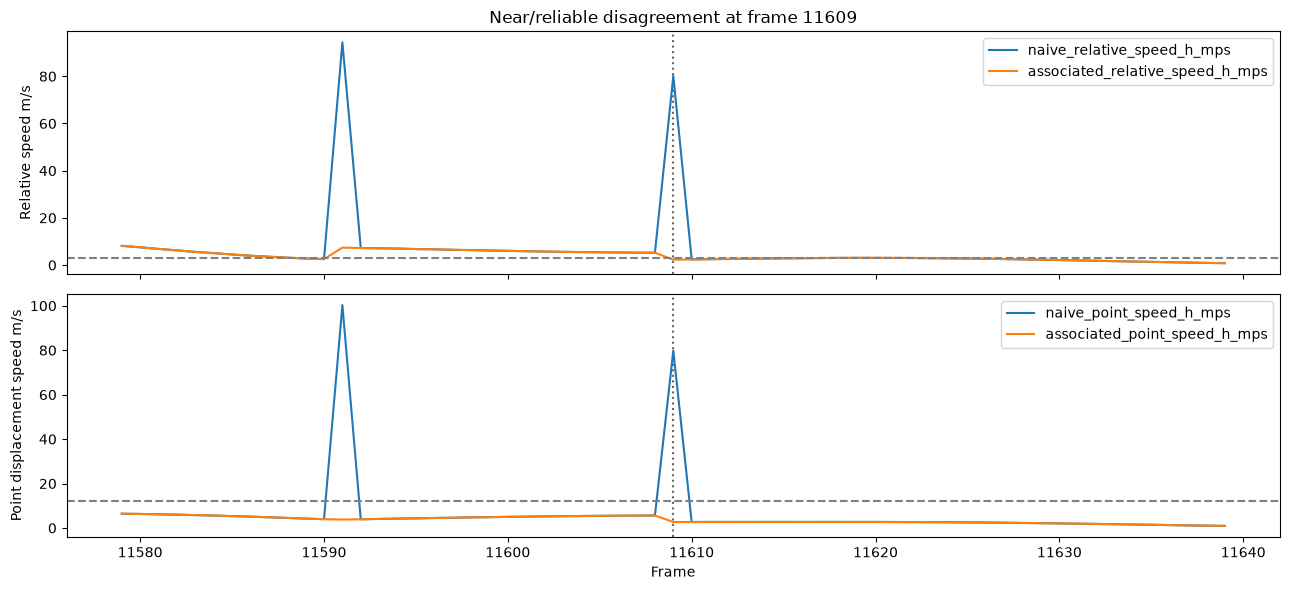

In [5]:
display(speeds)
flags=d.loc[d.natural&(d.naive_high_associated_low_near_h|d.naive_high_associated_low_near_a)]
if len(flags):
    center=int(flags.iloc[0].frame);half=int(flags.iloc[0].half)
    side='h' if bool(flags.iloc[0].naive_high_associated_low_near_h) else 'a'
else:
    valid=d.loc[d.natural&d.naive_relative_speed_h_mps.notna()]
    row=valid.loc[valid.naive_relative_speed_h_mps.idxmax()];center=int(row.frame);half=int(row.half);side='h'
w=d.loc[d.half.eq(half)&d.frame.between(center-30,center+30)]
fig,axes=plt.subplots(2,1,figsize=(13,6),sharex=True)
for ax in axes: ax.axvline(center,color='black',linestyle=':',alpha=.6)
axes[0].set_title(f'Near/reliable disagreement at frame {center}')
w.plot(x='frame',y=[f'naive_relative_speed_{side}_mps',f'associated_relative_speed_{side}_mps'],ax=axes[0])
axes[0].axhline(settings['maximum_relative_speed_mps'],color='grey',linestyle='--');axes[0].set_ylabel('Relative speed m/s')
w.plot(x='frame',y=[f'naive_point_speed_{side}_mps',f'associated_point_speed_{side}_mps'],ax=axes[1])
axes[1].axhline(settings['association_max_speed_mps'],color='grey',linestyle='--');axes[1].set_ylabel('Point displacement speed m/s')
axes[1].set_xlabel('Frame')
for ax in axes: ax.ticklabel_format(axis='x',style='plain',useOffset=False)
plt.tight_layout();plt.show()


## 7. Kandidat acquisition dan batas coverage

Tabel alasan berasal dari source dan bersifat eksklusif berdasarkan pemeriksaan berurutan; bukan ranking kausal. Tidak ada kandidat saat window bola/quality atau asosiasi tidak cukup. Banyak none bisa berarti syarat terlalu sempit atau data tidak tersedia; tidak membuktikan tidak ada acquisition.

Events mengelompokkan frame kandidat yang berurutan pada hipotesis kandidat lokal yang sama. Anchor memakai approach drop terbesar dalam episode, bukan waktu touch yang diketahui benar. Both_ambiguous dan contested_geometry mempertahankan ketidakpastian; tidak memilih owner. Kita belum bisa menyebut event ini reception atau interception yang benar hanya dari nearest-team sebelumnya.

,half,side,reason,frames
0,1,H,ball_or_quality_unavailable,33333
16,1,A,ball_or_quality_unavailable,33333
24,2,A,ball_or_quality_unavailable,32802
8,2,H,ball_or_quality_unavailable,32802
17,1,A,not_near,32795
25,2,A,not_near,29904
1,1,H,not_near,27273
9,2,H,not_near,26626
2,1,H,no_approach,14707
10,2,H,no_approach,13229


,half,candidate_status,frames
0,1,A_only,118
1,1,H_only,311
2,1,both_ambiguous,6
3,1,none,79032
4,2,A_only,176
5,2,H_only,249
6,2,both_ambiguous,6
7,2,none,76025


,prior_nearest_team,geometry_team_change,half,side,start_frame,end_frame,anchor_frame,candidate_frames,duration_s,both_candidates_any,contested_geometry_any,max_approach_drop_m,max_ball_speed_drop_mps,semantics
0,H,False,1,H,11934,11936,11934,3,0.12,False,False,0.796725,3.844213,reception_or_interception_proxy_not_possession...
1,H,False,1,H,12135,12138,12135,4,0.16,False,False,1.038434,3.036760,reception_or_interception_proxy_not_possession...
2,H,False,1,H,12223,12223,12223,1,0.04,False,False,0.607183,3.889272,reception_or_interception_proxy_not_possession...
3,H,False,1,H,12279,12280,12279,2,0.08,False,False,0.982403,2.827376,reception_or_interception_proxy_not_possession...
4,H,False,1,H,12366,12368,12366,3,0.12,False,False,0.783021,1.270586,reception_or_interception_proxy_not_possession...
5,H,False,1,H,13216,13219,13216,4,0.16,False,False,1.162203,4.368771,reception_or_interception_proxy_not_possession...
6,H,False,1,H,13402,13405,13402,4,0.16,False,False,1.241184,4.407904,reception_or_interception_proxy_not_possession...
7,H,False,1,H,13967,13969,13967,3,0.12,False,False,0.879765,2.588280,reception_or_interception_proxy_not_possession...
8,H,False,1,H,14425,14426,14425,2,0.08,False,False,0.890974,2.138526,reception_or_interception_proxy_not_possession...
9,H,False,1,H,14511,14513,14511,3,0.12,False,False,1.234597,3.693197,reception_or_interception_proxy_not_possession...


episodes  \
half side both_candidates_any contested_geometry_any             
1    A    False               False                         36   
                              True                           9   
          True                True                           3   
     H    False               False                        110   
                              True                           7   
          True                True                           3   
2    A    False               False                         53   
                              True                          12   
          True                True                           4   
     H    False               False                         83   
                              True                          11   
          True                True                           4   

                                                      median_episode_s  
half side both_candidates_any contested_geometry_any                    
1    A    False               False                               0.08  
                              True                                0.12  
          True                True                                0.12  
     H    False               False                               0.12  
                              True                                0.12  
          True                True                                0.08  
2    A    False               False                               0.08  
                              True                                0.10  
          True                True                                0.08  
     H    False               False                               0.12  
                              True                                0.08  
          True                True                                0.14

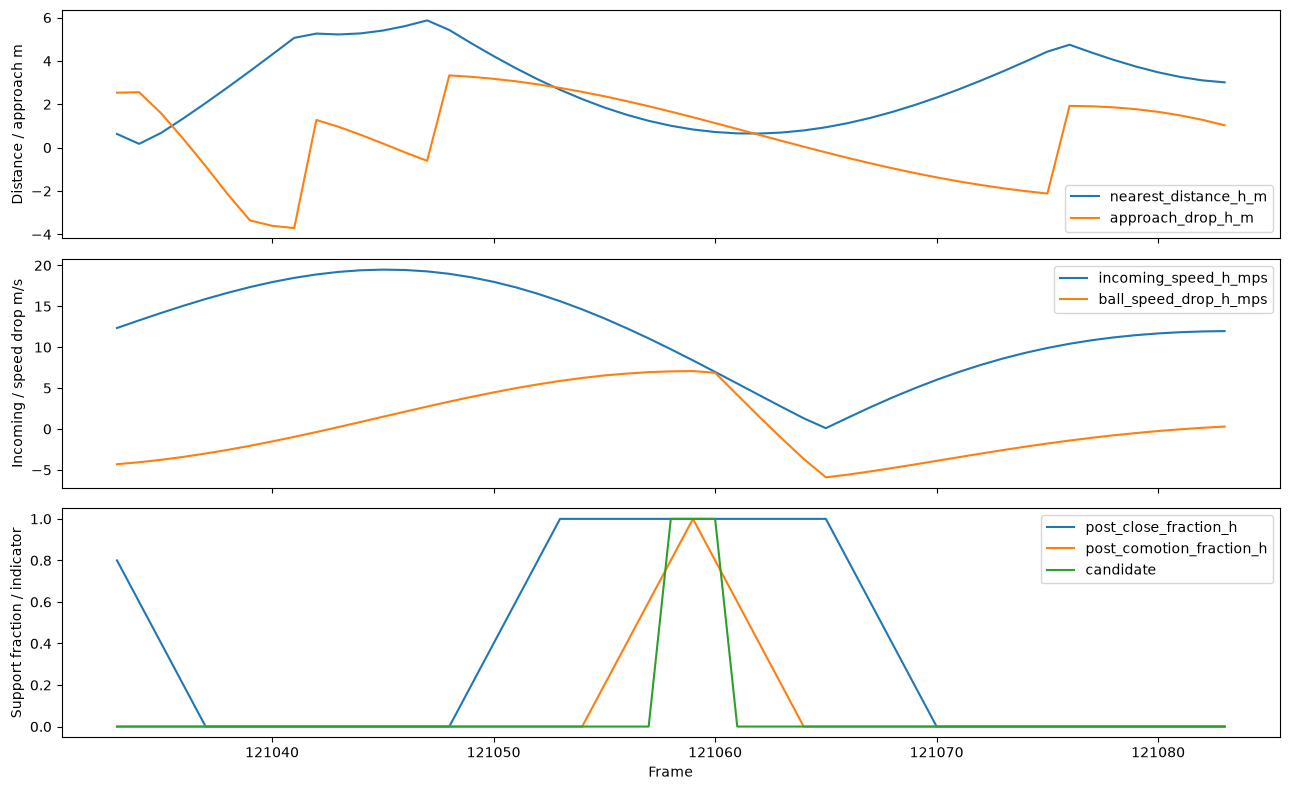

In [6]:
display(reasons.sort_values('frames',ascending=False))
display(d.loc[d.natural].groupby(['half','candidate_status']).size().rename('frames').reset_index())
display(events.head(30))
if len(events):
    display(events.groupby(['half','side','both_candidates_any','contested_geometry_any']).agg(
        episodes=('anchor_frame','size'),median_episode_s=('duration_s','median')))
    row=events.sort_values('max_approach_drop_m',ascending=False).iloc[0]
    center=int(row.anchor_frame);side=str(row.side).lower();half=int(row.half)
    w=d.loc[d.half.eq(half)&d.frame.between(center-25,center+25)].copy()
    fig,axes=plt.subplots(3,1,figsize=(13,8),sharex=True)
    w.plot(x='frame',y=[f'nearest_distance_{side}_m',f'approach_drop_{side}_m'],ax=axes[0]);axes[0].set_ylabel('Distance / approach m')
    w.plot(x='frame',y=[f'incoming_speed_{side}_mps',f'ball_speed_drop_{side}_mps'],ax=axes[1]);axes[1].set_ylabel('Incoming / speed drop m/s')
    w.assign(candidate=w[f'candidate_{side}'].astype(float)).plot(x='frame',y=[f'post_close_fraction_{side}',f'post_comotion_fraction_{side}','candidate'],ax=axes[2])
    axes[2].set_ylabel('Support fraction / indicator');axes[2].set_xlabel('Frame')
    for ax in axes: ax.ticklabel_format(axis='x',style='plain',useOffset=False)
    plt.tight_layout();plt.show()
else:print('Tidak ada episode kandidat; interpretasikan coverage dan alasan, jangan melonggarkan threshold hanya untuk menghasilkan event.')


## 8. Konteks prediksi lama, bukan evaluasi event

Source memadankan kandidat dengan label final dan transisi decoded A2b yang sudah ada. Model transitions bukan verified turnover. Ada/tidaknya kandidat di sekitar boundary bukan precision/recall atau bukti model salah. Window perbandingan juga memakai konteks setelah boundary.

In [7]:
event_context=read_table(diagnostic_dir,'diagnostics/player_acquisition_reference/event_context.csv')
transition_context=read_table(diagnostic_dir,'diagnostics/player_acquisition_reference/transition_context.csv')
display(read_json(diagnostic_dir,'diagnostics/player_acquisition_reference/metadata.json'))
display(event_context.groupby(['side','reference_label_at_anchor','both_candidates_any']).size().rename('episodes').reset_index())
display(transition_context.groupby(['to','candidate_H_nearby','candidate_A_nearby','both_candidate_nearby']).size().rename('decoded_transitions').reset_index())
print('A2b labels/transitions reused unchanged; overlap measures descriptive alignment only.')

{'semantics': 'descriptive alignment with existing predictions; model transitions are not verified turnovers; overlap is not recall/precision', 'window_radius_frames': 5, 'no_scorer': 'reference predictions are read only; no labels or hints generated'}

,side,reference_label_at_anchor,both_candidates_any,episodes
0,A,A,False,102
1,A,A,True,3
2,A,H,False,8
3,A,H,True,4
4,H,A,False,13
5,H,A,True,3
6,H,H,False,198
7,H,H,True,4


,to,candidate_H_nearby,candidate_A_nearby,both_candidate_nearby,decoded_transitions
0,A,False,False,False,528
1,A,False,True,False,3
2,H,False,False,False,527
3,H,True,False,False,5


A2b labels/transitions reused unchanged; overlap measures descriptive alignment only.


## 9. Skenario sintetis dan invariansi

Source membuat toy roster 3 H/2 A; quality fraction=1 berarti roster toy lengkap, bukan 11 pemain per tim. Kasus: passing dalam tim, interception, kontrol singkat sebelum release, touch sementara, nearest-point switch, permutasi slot, duplicate ambigu, occlusion, dropout pemain, contested reception dan co-moving opponent.

Permutasi kolom harus menjaga kandidat; duplicate/gap tidak dipaksakan; slow co-motion saja tidak cukup menjadi acquisition; contested mempertahankan ambiguitas. Semua adalah kontrak perilaku pada konstruksi sintetis, bukan event accuracy pertandingan atau bukti identitas benar.

,scenario,passed,expected_contract,candidate_H_frames,candidate_A_frames,both_ambiguous_frames,nearest_switch_H_frames,column_changed_H_frames,naive_high_associated_low_H_frames,ambiguous_nearest_H_frames,slot_permutation_invariant
0,same_team_pass,True,H,4,0,0,1,1,0,0,True
1,interception,True,A,0,4,0,1,1,0,0,True
2,short_control,True,A,0,4,0,2,2,0,0,True
3,temporary_touch,True,no_acquisition_candidate,0,0,0,2,2,0,0,True
4,nearest_switch,True,no_acquisition_candidate,0,0,0,1,1,1,0,True
5,slot_permutation,True,H,4,0,0,1,117,0,0,True
6,ambiguous_duplicate,True,no_acquisition_candidate,0,0,0,0,1,0,72,True
7,occlusion,True,no_acquisition_candidate,0,0,0,1,1,0,0,True
8,player_dropout,True,no_acquisition_candidate,0,0,0,2,3,0,0,True
9,contested_reception,True,both_ambiguous,4,4,4,1,1,0,0,True


{'source': 'deterministic toy roster (3 H, 2 A); fractions=1 mean complete toy observation, not an 11-player match', 'semantics': 'diagnostic candidate contracts, not model possession labels, event precision/recall or match ground truth', 'slot_permutation': 'H observation columns swap every other frame; geometry and local association must preserve event candidates', 'known_limit': 'both teams can satisfy encounter criteria; contested proxy remains ambiguous; unique spatial links are not proof of identity', 'no_scorer': 'no fusion, Viterbi, tag or label adjustment is performed'}

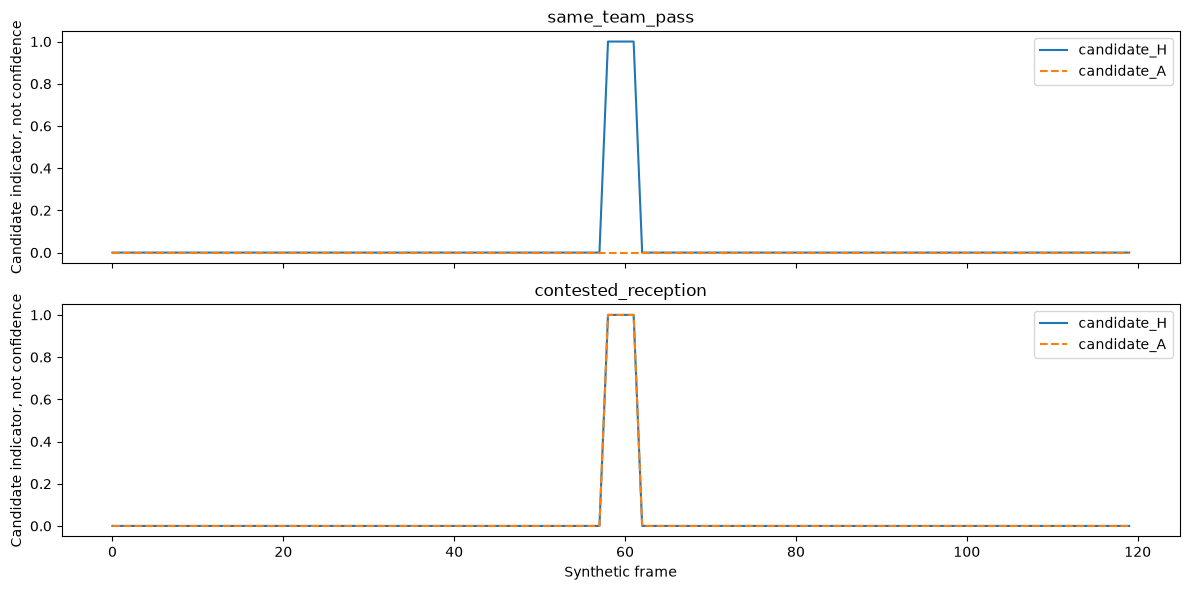

In [8]:
synthetic=read_table(diagnostic_dir,'diagnostics/player_acquisition_synthetic/summary.csv')
synthetic_frames=read_table(diagnostic_dir,'diagnostics/player_acquisition_synthetic/frames.csv')
display(synthetic)
display(read_json(diagnostic_dir,'diagnostics/player_acquisition_synthetic/metadata.json'))
assert len(synthetic)==11 and synthetic.passed.all()
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
for ax,name in zip(axes,['same_team_pass','contested_reception']):
    s=synthetic_frames.loc[synthetic_frames.scenario.eq(name)]
    s.assign(candidate_H=s.candidate_h.astype(float),candidate_A=s.candidate_a.astype(float)).plot(x='frame',y=['candidate_H','candidate_A'],ax=ax,style=['-','--'])
    ax.set_title(name);ax.set_ylabel('Candidate indicator, not confidence')
axes[-1].set_xlabel('Synthetic frame')
for ax in axes: ax.ticklabel_format(axis='x',style='plain',useOffset=False)
plt.tight_layout();plt.show()


## 10. Interpretasi dan keputusan berikutnya

| Temuan | Arah keputusan |
|---|---|
| Column change tidak selalu candidate switch | Slot tidak boleh dipakai sebagai identitas; pertahankan asosiasi lokal dengan quality flags |
| Banyak ambiguity/unmatched | Jangan memaksa asosiasi atau menganggap tidak ada acquisition; audit coverage |
| Naive tinggi, associated rendah pada subset near/reliable | Ada pengaruh pergantian nearest point; belum membuktikan skor lama salah |
| Passing/reception lolos tetapi touch/comoving tidak | Representasi lebih spesifik pada skenario itu; belum validasi match |
| Kedua tim memenuhi encounter | Tidak cukup informasi untuk memilih owner; kandidat tetap ambigu |
| Kandidat sedikit karena window tidak tersedia | Laporkan keterbatasan; jangan tuning threshold dari target jumlah event |
| Kandidat tidak sejajar boundary model | Model/diagnostik memakai evidence berbeda; bukan recall tanpa GT |
| Spatial links unik tetapi semantik kontrol tidak diketahui | Perlu evidence/validasi independen sebelum memasukkan ke score |

Tahap ini tidak membuat A3 atau mengubah F1/A1/A2a/A2b. Jika representasi memberi pembeda yang sah, eksperimen berikutnya memakai satu perubahan evidence pada F1 dan pengujian counterexample. Jika tidak, jangan menambah bonus yang hanya menduplikasi proximity. Tidak ada public-GT model selection.

In [9]:
natural=d.loc[d.natural]
display(Markdown(f"**Audit {manifest['run_id']}:** {len(events):,} episode kandidat pada frame alami; "
    f"H candidate frames {int(natural.candidate_h.sum()):,}, A {int(natural.candidate_a.sum()):,}, "
    f"both ambiguous {int(natural.candidate_status.eq('both_ambiguous').sum()):,}. "
    "Prediksi A2b tetap digunakan apa adanya. Episode/candidate counts bukan event accuracy atau jumlah acquisition yang diketahui benar."))
print('Near/reliable naive-high associated-low per half/side:')
display(speeds[['half','side','paired_measurement_frames','naive_high_associated_low_near_frames']])

**Audit 20261116_142221_367604_ee14b62c:** 335 episode kandidat pada frame alami; H candidate frames 572, A 306, both ambiguous 12. Prediksi A2b tetap digunakan apa adanya. Episode/candidate counts bukan event accuracy atau jumlah acquisition yang diketahui benar.

,half,side,paired_measurement_frames,naive_high_associated_low_near_frames
0,1,H,46771,4
1,2,H,44424,3
2,1,A,46989,3
3,2,A,44431,18


Near/reliable naive-high associated-low per half/side:


## 11. Simpulan run diagnostik dan keputusan

Run **20261116_142221_367604_ee14b62c** membaca fitur/posisi dari A2b **20261116_032142_912812_df9f9049**. Tidak ada scorer atau submission baru. Checksum input dan prediksi referensi tetap utuh. Delapan source pembentuk prediksi cocok byte demi byte atau hanya berbeda LF/CRLF; source pipeline hanya mendapat cabang audit opsional. Pengujian integrasi sintetis membuktikan mengaktifkan audit tidak mengubah skor, hint atau label.

**1. Asosiasi lokal dapat dihitung, tetapi coverage bukan ketepatan identitas.** Linked fraction dari titik teramati sekitar **99.76-99.87%** per babak/tim. Ini mengukur coverage hipotesis spasial, bukan association accuracy. Duplicate/ambiguous dan unmatched tetap ditolak. Keunikan spatial matching tidak meniadakan kemungkinan pergantian identitas yang tidak teramati, terutama saat crossing. Tidak ada persistent player ID yang dibentuk.

**2. Hipotesis nearest-point switch sebagai sumber utama kegagalan co-motion belum didukung pada subset yang dinilai.** Pada konteks dekat/andal, naive-high menjadi associated-low hanya **4 dan 3 frame H**, serta **3 dan 18 frame A** pada babak pertama/kedua (total 28 pengukuran side-frame, bukan otomatis 28 waktu unik). Median relative speed naive/associated juga hanya berubah sedikit. Banyak relative speed tinggi tetap tinggi setelah association. Temuan ini bersyarat pada link/observasi yang tersedia; bukan evaluasi seluruh frame ambiguous/missing dan bukan bukti semua keputusan nearest-geometry benar. Jangan mengganti feature atau memperpanjang tracking hanya karena asumsi bahwa slot switch menjelaskan sebagian besar fragmentasi.

**3. Ada 335 episode kandidat encounter per-side, belum acquisition yang diketahui benar.** H memenuhi kandidat pada **572 frame**, A pada **306 frame**, termasuk **12 frame** ketika kedua tim memenuhi kriteria. Durasi episode adalah lamanya indikator kandidat aktif, bukan durasi controlled possession atau spell H/A. Banyak episode singkat pada jendela event adalah wajar untuk indikator encounter dan tidak menambah label possession karena audit tidak masuk scorer.

**4. Coverage kandidat dibatasi syarat data dan definisi proxy.** Alasan utama yang tampil adalah window ball/quality unavailable, not_near, kemudian no_approach. Alasan memakai precedence sehingga tidak boleh dibaca sebagai ranking sebab independen. Association_unavailable juga ada. Absennya kandidat dapat berarti kurang observasi, tidak memenuhi definisi encounter, atau model proxy tidak mencakup kejadian itu; tidak boleh dipakai sebagai veto pergantian possession.

**5. Kandidat lebih sering berada dalam label tim yang sudah diprediksi daripada tepat pada boundary.** Dalam radius +/-5 frame, hanya **3 decoded transitions ke A** dan **5 ke H** yang memiliki kandidat terdekat. Ini bukan recall: transisi A2b bukan verified turnover, kandidat dapat berupa reception dalam tim, dan timing/definisi keduanya berbeda. prior_nearest_team/geometry_team_change juga bukan previous owner atau label interception. Kedekatan pada boundary maupun kesesuaian dengan label lama tidak menjadi dasar memilih threshold.

**6. Skenario sintetis menunjukkan perilaku yang diinginkan pada konstruksi tersebut.** Sebelas kontrak lolos: slot permutation menjaga kandidat, duplicate ditolak, gap tidak dijembatani, temporary touch/co-moving opponent saja tidak menciptakan kandidat, reception/interception dan kontrol singkat dapat muncul, dan contested reception mempertahankan both_ambiguous. Ini belum mengukur precision/recall pertandingan. Diagnosis hanya memakai XY; tidak mengkonfirmasi kontak atau ketinggian bola, dan post window memakai lookahead offline.

**Keputusan:** belum memasukkan kandidat ini ke score, belum membuat A3, dan tidak mengganti F1 dengan eksperimen baru berdasarkan jumlah event. Audit asosiasi memperjelas pengukuran tetapi cakupan perbedaan pengukuran yang melintasi threshold co-motion pada konteks near/reliable kecil. Sinyal event tidak boleh menjadi gate universal karena observasi/coverage tidak cukup.

**Rencana pengembangan yang didukung hasil:**

1. Uji reception/interception yang tidak disertai slowdown/turn, dribbling dengan perubahan jarak bola, crossing, dan aerial/2D ambiguity pada data sintetis agar kelemahan syarat encounter terukur. Jangan mengubah ambang untuk mengejar jumlah kandidat atau overlap boundary.
2. Pisahkan event penerimaan oleh pemain dari acquisition oleh tim penantang. Untuk eksperimen score berikutnya, konteks pemegang possession sebelumnya tidak dapat diganti dengan nearest-team sebelumnya. Audit timing lag dan kualitas evidence terlebih dahulu.
3. Bila kandidat memberikan informasi pembeda yang dapat diuji, buat satu eksperimen evidence positif pada F1; absence of event tetap bukan bukti negatif. Bandingkan counterexample co-moving opponent dan passing agar tidak mengulang A1/A2b.
4. Prioritaskan validasi independen yang diizinkan jika tersedia. Tanpanya, pertahankan klaim pada perilaku/coverage diagnostik, bukan accuracy atau spellF1.
